In [146]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# The Data

The data is two different sheets: hour, and day. 

	- instant: record index
	- dteday : date
	- season : season (1:springer, 2:summer, 3:fall, 4:winter)
	- yr : year (0: 2011, 1:2012)
	- mnth : month ( 1 to 12)
	- hr : hour (0 to 23)
	- holiday : weather day is holiday or not (extracted from http://dchr.dc.gov/page/holiday-schedule)
	- weekday : day of the week
	- workingday : if day is neither weekend nor holiday is 1, otherwise is 0.
	+ weathersit : 
		- 1: Clear, Few clouds, Partly cloudy, Partly cloudy
		- 2: Mist + Cloudy, Mist + Broken clouds, Mist + Few clouds, Mist
		- 3: Light Snow, Light Rain + Thunderstorm + Scattered clouds, Light Rain + Scattered clouds
		- 4: Heavy Rain + Ice Pallets + Thunderstorm + Mist, Snow + Fog
	- temp : Normalized temperature in Celsius. The values are divided to 41 (max)
	- atemp: Normalized feeling temperature in Celsius. The values are divided to 50 (max)
	- hum: Normalized humidity. The values are divided to 100 (max)
	- windspeed: Normalized wind speed. The values are divided to 67 (max)
	- casual: count of casual users
	- registered: count of registered users
	- cnt: count of total rental bikes including both c
     - 

 hr is not present in the day sheet. Gonna start with day because it seems less annoying to deal with right now.asual and registered

In [31]:
df = pd.read_csv("Data/day.csv")

# fixing index

# converting dteday column into a datetime object, moving, then deleting original dteday column
df['date'] = pd.to_datetime(df['dteday'])
df = df.drop(columns = ["instant", "dteday"])
df = df.rename(columns = {"temp": "temp_norm", "atemp": "atemp_norm"})

In [32]:
# for more presentable data. yay!
df_presentable = df
df_presentable['weekday'] = df_presentable['weekday'].map({6: "Saturday", 0: "Sunday", 1: "Monday", 2: "Tuesday", 3: "Wednesday", 4: "Thursday", 5: "Friday"})
df_presentable['season'] = df_presentable['season'].map({1: "Spring", 2: "Summer", 3: "Fall", 4: "Winter"})

df_presentable['temp_norm'] = (df_presentable['temp_norm'])
df_presentable['atemp_norm'] = ((df_presentable['atemp_norm'] * 50) * 1.8) + 32
df_presentable['windspeed'] = df_presentable['windspeed'] * 67
df_presentable = df_presentable.rename(columns = {"temp_norm": "temperature_fahrenheit", "atemp_norm": "feeling_temperature_fahrenheit"})
df_presentable['yr'] = df_presentable['yr'] + 2011

df_presentable.head(10)

,season,yr,mnth,holiday,weekday,workingday,weathersit,temperature_fahrenheit,feeling_temperature_fahrenheit,hum,windspeed,casual,registered,cnt,date
0,Spring,2011,1,0,Saturday,0,2,0.344167,64.72625,0.805833,10.749882,331,654,985,2011-01-01
1,Spring,2011,1,0,Sunday,0,2,0.363478,63.83651,0.696087,16.652113,131,670,801,2011-01-02
2,Spring,2011,1,0,Monday,1,1,0.196364,49.04645,0.437273,16.636703,120,1229,1349,2011-01-03
3,Spring,2011,1,0,Tuesday,1,1,0.200000,51.09098,0.590435,10.739832,108,1454,1562,2011-01-04
4,Spring,2011,1,0,Wednesday,1,1,0.226957,52.63430,0.436957,12.522300,82,1518,1600,2011-01-05
5,Spring,2011,1,0,Thursday,1,1,0.204348,52.98881,0.518261,6.000868,88,1518,1606,2011-01-06
6,Spring,2011,1,0,Friday,1,2,0.196522,50.79551,0.498696,11.304642,148,1362,1510,2011-01-07
7,Spring,2011,1,0,Saturday,0,2,0.165000,46.60286,0.535833,17.875868,68,891,959,2011-01-08
8,Spring,2011,1,0,Sunday,0,1,0.138333,42.45575,0.434167,24.250650,54,768,822,2011-01-09
9,Spring,2011,1,0,Monday,1,1,0.150833,45.57992,0.482917,14.958889,41,1280,1321,2011-01-10


In [33]:
# checking if there are any na or nulls in the dataframe. no, which is really good actually
df.isna().any()

season        False
yr            False
mnth          False
holiday       False
weekday       False
workingday    False
weathersit    False
temp_norm     False
atemp_norm    False
hum           False
windspeed     False
casual        False
registered    False
cnt           False
date          False
dtype: bool

In [34]:
# most of the data types are coherent. that's good, at least
print(df.dtypes)

season                object
yr                     int64
mnth                   int64
holiday                int64
weekday               object
workingday             int64
weathersit             int64
temp_norm            float64
atemp_norm           float64
hum                  float64
windspeed            float64
casual                 int64
registered             int64
cnt                    int64
date          datetime64[ns]
dtype: object


# To Whoever Checks This Next:
Should we unnormalize the data, or not? 

In [35]:
print(f"Normal DF Size: {len(df)}. Dropping Duplicates: {len(df.drop_duplicates())}")

Normal DF Size: 731. Dropping Duplicates: 731


In [36]:
df.corr(numeric_only=True)

,yr,mnth,holiday,workingday,weathersit,temp_norm,atemp_norm,hum,windspeed,casual,registered,cnt
yr,1.000000,-0.001792,0.007954,-0.002013,-0.048727,0.047604,0.046106,-0.110651,-0.011817,0.248546,0.594248,0.566710
mnth,-0.001792,1.000000,0.019191,-0.005901,0.043528,0.220205,0.227459,0.222204,-0.207502,0.123006,0.293488,0.279977
holiday,0.007954,0.019191,1.000000,-0.253023,-0.034627,-0.028556,-0.032507,-0.015937,0.006292,0.054274,-0.108745,-0.068348
workingday,-0.002013,-0.005901,-0.253023,1.000000,0.061200,0.052660,0.052182,0.024327,-0.018796,-0.518044,0.303907,0.061156
weathersit,-0.048727,0.043528,-0.034627,0.061200,1.000000,-0.120602,-0.121583,0.591045,0.039511,-0.247353,-0.260388,-0.297391
temp_norm,0.047604,0.220205,-0.028556,0.052660,-0.120602,1.000000,0.991702,0.126963,-0.157944,0.543285,0.540012,0.627494
atemp_norm,0.046106,0.227459,-0.032507,0.052182,-0.121583,0.991702,1.000000,0.139988,-0.183643,0.543864,0.544192,0.631066
hum,-0.110651,0.222204,-0.015937,0.024327,0.591045,0.126963,0.139988,1.000000,-0.248489,-0.077008,-0.091089,-0.100659
windspeed,-0.011817,-0.207502,0.006292,-0.018796,0.039511,-0.157944,-0.183643,-0.248489,1.000000,-0.167613,-0.217449,-0.234545
casual,0.248546,0.123006,0.054274,-0.518044,-0.247353,0.543285,0.543864,-0.077008,-0.167613,1.000000,0.395282,0.672804


In [37]:
df.describe().T

,count,mean,min,25%,50%,75%,max,std
yr,731.0,0.500684,0.0,0.0,1.0,1.0,1.0,0.500342
mnth,731.0,6.519836,1.0,4.0,7.0,10.0,12.0,3.451913
holiday,731.0,0.028728,0.0,0.0,0.0,0.0,1.0,0.167155
workingday,731.0,0.683995,0.0,0.0,1.0,1.0,1.0,0.465233
weathersit,731.0,1.395349,1.0,1.0,1.0,2.0,3.0,0.544894
temp_norm,731.0,0.495385,0.05913,0.337083,0.498333,0.655417,0.861667,0.183051
atemp_norm,731.0,74.691859,39.116264,62.405825,75.80597,86.77418,107.68064,14.666506
hum,731.0,0.627894,0.0,0.52,0.626667,0.730209,0.9725,0.142429
windspeed,731.0,12.762576,1.500244,9.04165,12.125325,15.625371,34.000021,5.192357
casual,731.0,848.176471,2.0,315.5,713.0,1096.0,3410.0,686.622488


<Axes: xlabel='weekday'>

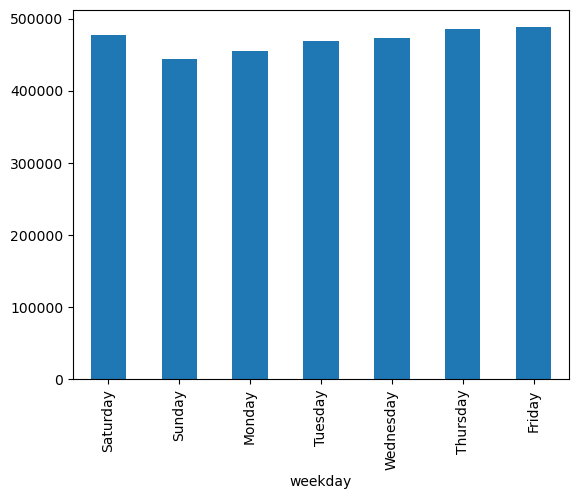

In [38]:
df_presentable.groupby("weekday", sort = False)["cnt"].sum().plot.bar()

<Axes: xlabel='season'>

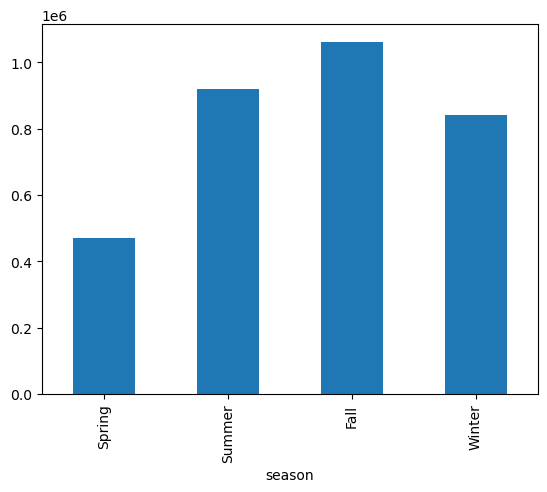

In [39]:
df_presentable.groupby("season", sort = False)["cnt"].sum().plot.bar()

<Axes: xlabel='workingday'>

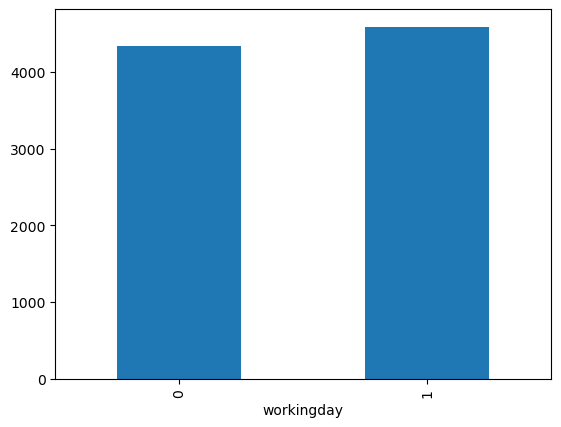

In [40]:
df_presentable.groupby("workingday", sort = False)["cnt"].mean().plot.bar()

<Axes: xlabel='holiday'>

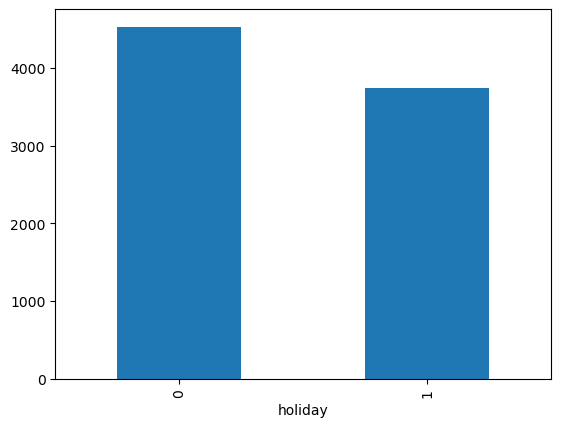

In [41]:
df_presentable.groupby("holiday", sort = False)["cnt"].mean().plot.bar()

<Axes: ylabel='Frequency'>

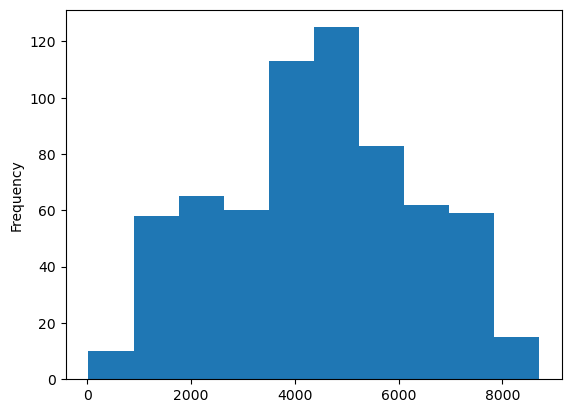

In [42]:
df_presentable.groupby("windspeed", sort = False)["cnt"].mean().plot.hist()

In [43]:
df.to_csv("Data/regular_df.csv")
df_presentable.to_csv("Data/presentable_df.csv")